# How Melbourne's city centre was built, year by year

The City of Melbourne's Census of Land Use and Employment (CLUE) records each property's building with the year it was
built and its floors, as points. The council's 2023 building footprints give each building's outline, part by part,
with heights. Neither says the other: the years have no shapes, the shapes have no years. Here the two are joined (each
building takes the CLUE record that sits in it) and the buildings standing in the CBD today are counted by when they
were built. In [Plotlay](https://www.getplotlay.com) the same parts are a data layer raised in 3D at their own heights and
grown by year.

This notebook reads only the files in `../data`.

**Read it carefully.** These are today's buildings by the year they were built. Buildings demolished since are not in
the data, so this is not the city as it stood in each year. The council's construction year is often rounded (1900,
1910, 1920) or may be the year of later major works.

In [1]:
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
DATA = '../data'
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## The two sources

`clue/buildings_cbd_2024.csv` is the CLUE building information for census year 2024, the rows in the Melbourne (CBD)
small area. `geometry/parts.geojson` is every footprint part of a structure in the CBD from the 2023 Building
Footprints, with `height_m` (its top over the structure's base) and `base_m` (where the part starts: a tower on its
podium), and the year joined to it.

In [2]:
clue = pd.read_csv(f'{DATA}/clue/buildings_cbd_2024.csv')
clue['year'] = pd.to_numeric(clue.construction_year.astype(str).str[:4], errors='coerce')
parts = gpd.read_file(f'{DATA}/geometry/parts.geojson')
print(len(clue), 'CLUE records in the CBD,', clue.year.isna().sum(), 'with no construction year')
print(len(parts), 'footprint parts of', parts.structure_id.nunique(), 'structures')

1542 CLUE records in the CBD, 59 with no construction year
4442 footprint parts of 1547 structures


## The join, done again

Each structure (all its parts together) takes the CLUE record whose point is inside it; a record inside none goes to
the nearest structure within 8 m. Where several records fall in one structure (strata titles, a shop in a tower) the
one with the most floors wins, then the earliest year. The result should match `tables/buildings.csv`.

In [3]:
P = parts.to_crs(7855)
S = P.dissolve(by='structure_id').reset_index()[['structure_id', 'geometry']]
pts = gpd.GeoDataFrame(clue, geometry=gpd.points_from_xy(clue.longitude, clue.latitude), crs=4326).to_crs(7855)
inside = gpd.sjoin(pts, S, predicate='intersects', how='left')
inside = inside[~inside.index.duplicated()]
miss = inside[inside.structure_id.isna()].drop(columns=['structure_id', 'index_right'])
near = gpd.sjoin_nearest(miss, S, max_distance=8, how='left')
near = near[~near.index.duplicated()]
inside.loc[near.index, 'structure_id'] = near.structure_id
m = inside.dropna(subset=['structure_id']).copy()
m['floors'] = m.number_of_floors_above_ground.fillna(0)
best = m.sort_values(['structure_id', 'floors', 'year'], ascending=[True, False, True]).groupby('structure_id').head(1)
mine = S[['structure_id']].merge(best[['structure_id', 'year']], how='left')
theirs = pd.read_csv(f'{DATA}/tables/buildings.csv', dtype={'structure_id': str})
both = mine.merge(theirs[['structure_id', 'year']], on='structure_id', suffixes=('', '_plotlay'))
same = ((both.year == both.year_plotlay) | (both.year.isna() & both.year_plotlay.isna())).mean()
print(f'{len(S)} structures; records matched inside {int((~inside.structure_id.isna()).sum() - len(near.dropna(subset=["structure_id"])))}, near {len(near.dropna(subset=["structure_id"]))}, not matched {int(inside.structure_id.isna().sum())}')
print(f'same year as the table: {same:.1%}')

1547 structures; records matched inside 1443, near 66, not matched 33
same year as the table: 100.0%


## The share with no year

A structure has no year when no CLUE record sits in it (laneway sheds, plant rooms, parts the census counts under
another property) or when its record has a blank year. In Plotlay these are shown faint.

In [4]:
b = theirs
ny = b.year.isna()
print(f'{ny.sum()} of {len(b)} structures ({ny.mean():.1%}) have no year')
print('median height with no year', b[ny].height_m.median(), 'm; with a year', b[~ny].height_m.median(), 'm')

228 of 1548 structures (14.7%) have no year
median height with no year 10.0 m; with a year 18.5 m


## Eras

Buildings standing today by the era they were built, and their floor space, estimated as each part's area times its
height over 3.5 m a floor (to compare eras only; never a building's floor area).

In [5]:
P['floor_m2'] = P.area * (P.height_m - P.base_m).clip(lower=0) / 3.5
vol = P.groupby('structure_id').floor_m2.sum()
d = b.dropna(subset=['year']).copy(); d['floor_m2'] = d.structure_id.map(vol)
bins = [0, 1860, 1900, 1945, 1990, 2100]
names = ['Before 1861', '1861 to 1900', '1901 to 1945', '1946 to 1990', '1991 to 2024']
d['era'] = pd.cut(d.year, bins, labels=names)
e = d.groupby('era', observed=False).agg(buildings=('structure_id', 'size'), floor_m2=('floor_m2', 'sum'), median_height_m=('height_m', 'median'))
e['share_of_buildings'] = (e.buildings / e.buildings.sum()).round(3)
e['share_of_floor'] = (e.floor_m2 / e.floor_m2.sum()).round(3)
e.round({'floor_m2': 0, 'median_height_m': 1})

,buildings,floor_m2,median_height_m,share_of_buildings,share_of_floor
era,,,,,
Before 1861,58,180973.0,10.5,0.044,0.013
1861 to 1900,248,642367.0,12.5,0.188,0.048
1901 to 1945,518,1659876.0,15.0,0.392,0.123
1946 to 1990,312,4486468.0,42.5,0.236,0.333
1991 to 2024,184,6523282.0,81.0,0.139,0.483


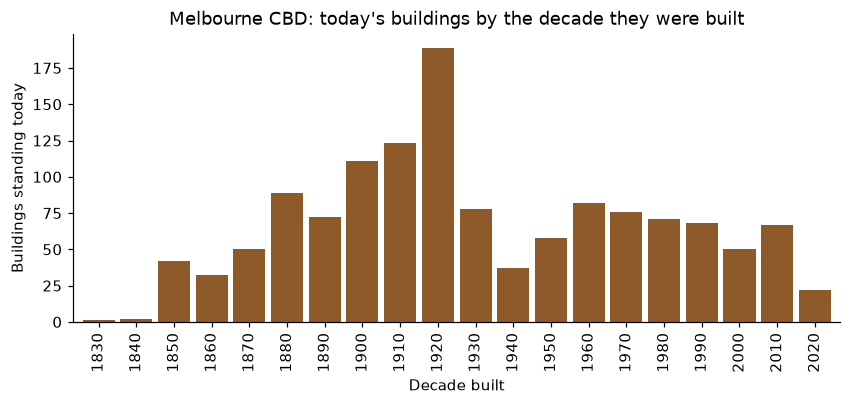

round years (1900, 1910 ... and 1901): 28% of dated buildings


In [6]:
dec = d.groupby((d.year // 10 * 10).astype(int)).structure_id.size()
ax = dec.plot.bar(figsize=(9, 3.4), color='#8f5a2a', width=0.85)
ax.set_xlabel('Decade built'); ax.set_ylabel('Buildings standing today'); ax.set_title("Melbourne CBD: today's buildings by the decade they were built")
plt.show()
print('round years (1900, 1910 ... and 1901):', f"{(d.year.mod(10).eq(0) | d.year.eq(1901)).mean():.0%}", 'of dated buildings')

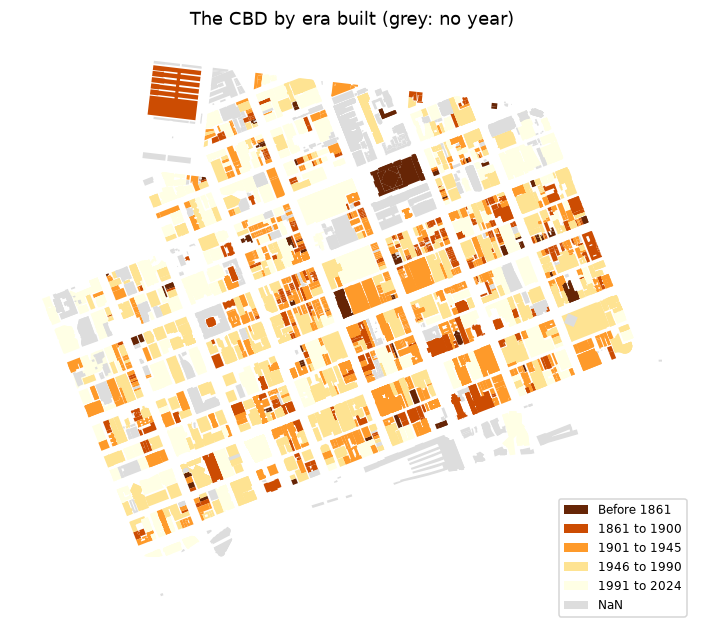

In [7]:
P2 = P.merge(b[['structure_id']], on='structure_id')
P2['era'] = pd.cut(P2.year, bins, labels=names)
ax = P2.plot(column='era', cmap='YlOrBr_r', legend=True, figsize=(8, 8), missing_kwds={'color': '#dddddd'}, legend_kwds={'loc': 'lower right', 'fontsize': 8})
ax.set_axis_off(); ax.set_title('The CBD by era built (grey: no year)')
plt.show()

## Sources and licence

Building information (CLUE, census year 2024), 2023 Building Footprints and Small Areas for CLUE: City of Melbourne
Open Data, CC BY 4.0. Full credits in `NOTICE`.